# 04 · Optional Monte Carlo validation
The main uncertainty workflow is in notebooks 05 and 06. Monte Carlo checks the consistency of a noisy observer EKF; it is not required to propagate observer covariance or map it into Gateway pointing uncertainty.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists() and (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs/baseline.json")
cfg["simulation"]["periods"] = 1.0


/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/study.py:52: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  result=make_truth(cfg); result['config']=cfg


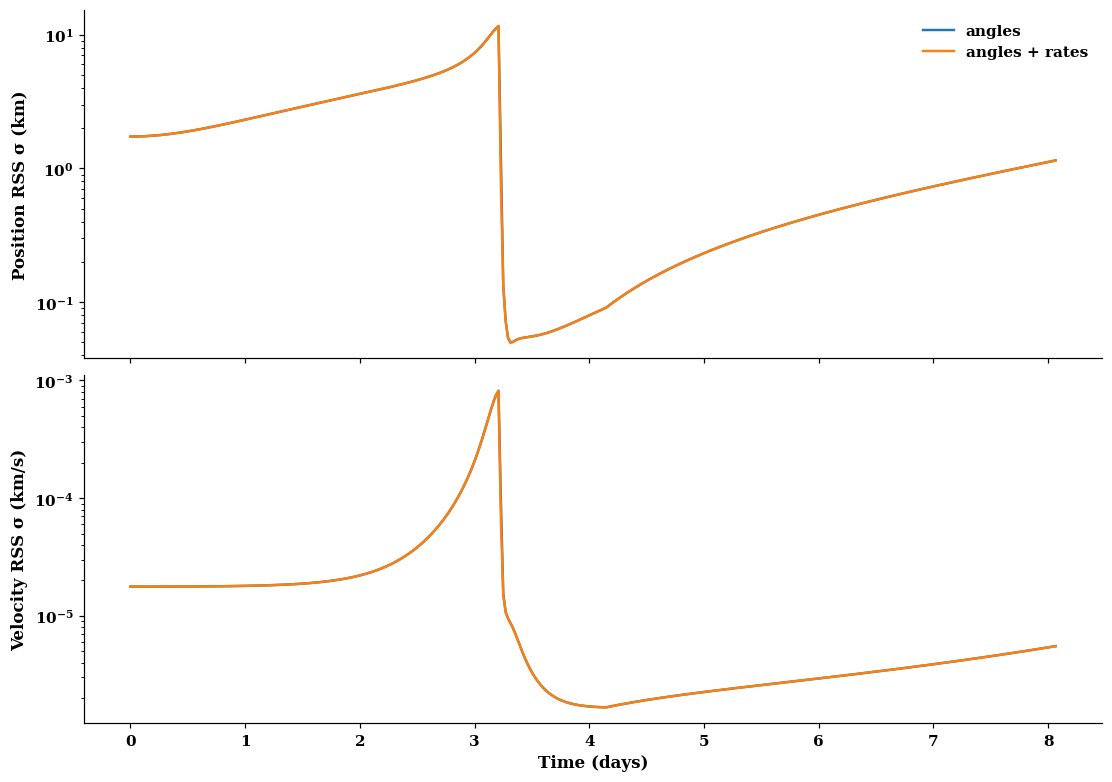

In [2]:
from halo_tracking.study import run_study
from halo_tracking.plotting import uncertainty_comparison
forecast = run_study(cfg, covariance_only=True)
fig = uncertainty_comparison(forecast)

## Optional paired Monte Carlo comparison: 100 trials
Set `RUN_MONTE_CARLO = True` below to rerun validation. A completed 100-trial reference summary is saved in `data/reference_results/monte_carlo_summary.json`.
Each measurement case uses the same 100 initial-state perturbations and angle-noise realizations. Inspect RMSE, covariance coverage and ensemble NEES before interpreting uncertainty. Zero process noise gives deterministic model-matched truth. This experiment covers the baseline one-period arc; notebook 05 is a separate long-horizon covariance forecast.

In [3]:
from halo_tracking.validation import monte_carlo
RUN_MONTE_CARLO = False  # Optional validation; main covariance workflow does not need this.
def report_progress(case, completed, total):
    if completed % 10 == 0:
        print(f"{case}: {completed}/{total} trials", flush=True)
if RUN_MONTE_CARLO:
    mc = monte_carlo(cfg, trials=100, progress=report_progress)
else:
    import json
    reference = ROOT / "data/reference_results/monte_carlo_summary.json"
    print(reference.read_text() if reference.exists() else "Monte Carlo validation is disabled.")

{
  "scope": "100 paired trials over the baseline one-period arc; Gateway is not part of this observer filter validation",
  "metrics": {
    "angles": {
      "trials": 100,
      "final_mean_nees": 97.12858651479634,
      "mean_nis": 2.616027988893608,
      "final_position_rmse_km": 2.75741553016082,
      "final_mean_component_3sigma_coverage": 0.9066666666666667
    },
    "angles_rates": {
      "trials": 100,
      "final_mean_nees": 100.94436284388675,
      "mean_nis": 4.661472787139168,
      "final_position_rmse_km": 2.763379818290232,
      "final_mean_component_3sigma_coverage": 0.9066666666666667
    }
  }
}



In [4]:
if RUN_MONTE_CARLO:
    import numpy as np
    import matplotlib.pyplot as plt
    days = mc["times"] * cfg["time_unit_s"] / 86400
    fig_mc, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout="constrained")
    for name in ["angles", "angles_rates"]:
        axes[0].semilogy(days, mc[name]["position_rmse_km"], label=name)
        axes[1].plot(days, mc[name]["mean_nees"], label=name)
        axes[2].plot(days, mc[name]["component_3sigma_coverage"].mean(axis=1), label=name)
    axes[0].set_ylabel("Position RMSE (km)")
    axes[1].set_ylabel("Ensemble mean NEES")
    axes[1].axhline(6, color="black", ls="--", label="Six-state reference mean")
    axes[2].set(ylabel="Mean component 3σ coverage", xlabel="Time (days)", ylim=(0, 1.05))
    axes[0].legend()
    for name in ["angles", "angles_rates"]:
        print(name, "Final NEES:", mc[name]["mean_nees"][-1],
              "Visible NIS mean:", np.nanmean(mc[name]["nis"]))


NEES/NIS confidence intervals require independent trial ensembles; time samples are correlated. This baseline compares measurement cases under one dynamics model. Higher-fidelity truth and alternative estimators are future comparisons, not implemented results.

In [5]:
if RUN_MONTE_CARLO:
    from halo_tracking.plotting import export
    export(fig_mc, ROOT / "results/comparison/monte_carlo.png")
    output = ROOT / "results/comparison"
    output.mkdir(parents=True, exist_ok=True)
    arrays = {"times": mc["times"], "visible": mc["visible"]}
    for name in ["angles", "angles_rates"]:
        for key, value in mc[name].items():
            arrays[name + "_" + key] = value
    np.savez_compressed(output / "monte_carlo.npz", **arrays)


## Baseline finding
The Monte Carlo comparison must be inspected for final mean NEES above the six-state reference mean. The current covariance is not yet demonstrated to be statistically consistent. Investigate prior size, nonlinear behavior near lunar passage, cadence, and Monte Carlo convergence before using the uncertainty bounds for design decisions.